# 07 — Eindvergelijking en foutenanalyse

De finale RF-keuze lag vóór de test vast. We vergelijken originele en gecontroleerde reproducties; geen nieuwe tuning of testvoorspellingen.

## Bijdragen — Messi10

**Raoul Buffels:** dataverwerking en cleaning, EDA en hypothesen, features, modellen,
tuning, evaluatie en documentatie; Citi Bike-frontend en backend.
**Jorre Van Dyck:** hulp bij deployment op Render.
Codex hielp met implementatie, uitleg, tests en uitvoering. Ieder teamlid moet de
eigen keuzes mondeling kunnen uitleggen.

We bepalen de projectmap en laden de kleine tabellen. Grote bronbestanden blijven op schijf.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown
locations=[Path.cwd(),Path.cwd().parent,Path.cwd()/'Citybike_full']
ROOT=next(p for p in locations if (p/'citibike').exists())
sys.path.insert(0,str(ROOT))
from citibike.config import REPORTS, DATA, MODELS
def report(name):
    return json.loads((REPORTS/name).read_text(encoding='utf-8'))
def table(name):
    display(pd.read_csv(REPORTS/name,dtype={'start_station_id':'string','end_station_id':'string','station_id':'string'}))


## Centrale vergelijking

Testkolommen zijn alleen gevuld voor de vastgelegde winnaar en baseline. De oorspronkelijke tijd is CV + fit + opslag. PyCaret-CV staat apart van de handmatige validatiemetrics.

In [2]:
from citibike.reporting import comparison_table
from citibike.plots import show
display(comparison_table())
table('pycaret_comparison.csv')
display(pd.DataFrame(report('notebook_reproduction/pycaret_validation.json')))

,Model,Features,Train RMSE,Validation RMSE,Validation MAE,Validation R2,CV RMSE,Test RMSE,Test MAE,Test R2,CV + fit + opslag (s),Opmerkingen
0,seasonal_naive,"lag_7d, clock_hours",1309.747668,2826.164920,1510.127732,0.668076,2086.672928,2608.777506,1453.528226,0.701289,0.229516,Eenvoudige referentie: hetzelfde uur vorige week.
1,ridge,"hour_sin, hour_cos, weekday_sin, weekday_cos, ...",1021.691347,1982.440036,1248.058114,0.836678,1594.314667,NaN,NaN,NaN,0.866120,"Lineair, geschaald per trainfold; makkelijker ..."
2,random_forest,"hour_sin, hour_cos, weekday_sin, weekday_cos, ...",684.188257,1945.709748,1118.646342,0.842674,1460.783347,NaN,NaN,NaN,394.205085,Niet-lineair; duidelijk verschil tussen train ...
3,lightgbm,"hour_sin, hour_cos, weekday_sin, weekday_cos, ...",778.042812,1952.244762,1152.417360,0.841616,1423.037130,NaN,NaN,NaN,10.576864,"Boosting; snelle fit, vergelijkbare validatief..."
4,tuned_lightgbm,"hour_sin, hour_cos, weekday_sin, weekday_cos, ...",744.497812,1972.512094,1204.596739,0.838310,1383.390475,NaN,NaN,NaN,8.319329,Betere trainings-CV gaf geen betere validaties...
5,tuned_random_forest,"hour_sin, hour_cos, weekday_sin, weekday_cos, ...",536.134489,1940.492880,1114.479601,0.843517,1433.759353,1979.507160,1076.225847,0.828015,811.226580,"Vastgelegde winnaar; kleine tuningwinst, groot..."
6,ridge_calendar,"hour_sin, hour_cos, weekday_sin, weekday_cos, ...",2325.245735,5315.257689,3986.439396,-0.174067,2590.232107,NaN,NaN,NaN,0.438945,Kalender alleen mist de recente gebruiksintens...
7,ridge_no_14d,"hour_sin, hour_cos, weekday_sin, weekday_cos, ...",1060.539908,2174.787271,1376.786629,0.803448,1557.951926,NaN,NaN,NaN,0.503810,Ablatie: minder goed op de gekozen validatiepe...


,Unnamed: 0,candidate,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
0,3,lightgbm,Light Gradient Boosting Machine,919.4277,2.219320e+06,1433.3589,0.7183,0.8604,1.0487,1.208
1,2,random_forest,Random Forest Regressor,917.6491,2.280610e+06,1460.7833,0.7014,0.8548,1.1461,51.088
2,1,ridge,Ridge Regression,1025.6297,2.668287e+06,1594.3144,0.6369,0.9592,1.1846,0.118
3,0,seasonal_naive,SeasonalNaive,1349.9824,4.550459e+06,2086.6729,0.3707,1.1928,1.2417,0.710


,name,RMSE,MAE,R2,train_RMSE,train_MAE,train_R2
0,lightgbm,1956.952952,1158.502503,0.840851,778.365740,433.032423,0.928690
1,random_forest,1945.709748,1118.646342,0.842674,684.188257,359.153829,0.944902
2,ridge,1982.439599,1248.057527,0.836678,1021.691354,578.390271,0.877136
3,seasonal_naive,2826.164920,1510.127732,0.668076,1309.747668,677.011659,0.798089


## Gecontroleerde nieuwe fits

De scores komen uit notebooks 03, 05 en 06 en moeten gelijk zijn aan de oorspronkelijke studie. Nieuwe fitduur staat apart van historische CV + fit + opslag.

In [3]:
reproduced=pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in sorted((REPORTS/'notebook_reproduction').glob('*.json')) if p.stem not in ['pycaret_audit','pycaret_validation']])
display(reproduced[['name','train_RMSE','RMSE','MAE','R2','fit_seconds','original_metrics_equal']])
show('comparison')

,name,train_RMSE,RMSE,MAE,R2,fit_seconds,original_metrics_equal
0,lightgbm,778.042812,1952.244762,1152.417360,0.841616,0.716802,True
1,random_forest,684.188257,1945.709748,1118.646342,0.842674,37.922764,True
2,ridge,1021.691347,1982.440036,1248.058114,0.836678,0.045709,True
3,ridge_calendar,2325.245735,5315.257689,3986.439396,-0.174067,0.019236,True
4,ridge_no_14d,1060.539908,2174.787271,1376.786629,0.803448,0.034526,True
5,seasonal_naive,1309.747668,2826.164920,1510.127732,0.668076,0.003045,True
6,tuned_lightgbm,744.497812,1972.512094,1204.596739,0.838310,0.558306,True
7,tuned_random_forest,536.134489,1940.492880,1114.479601,0.843517,71.244654,True


<Figure size 1200x500 with 2 Axes>

De laagste validatie-RMSE is 1940.49 bij tuned_random_forest; de train-RMSE is 536.13, een verschil van 1404.36 ritten/uur. Een hogere validatiefout kan op overfit of veranderde omstandigheden wijzen. De vastgelegde selectieregel mag binnen 1% het eenvoudigere model kiezen. Een lage trainingsfout alleen rechtvaardigt geen modelkeuze.

## Keuze en generalisatie

RF valideert circa 31,34% beter dan de weekbaseline. De grote train/validatiekloof en slechts circa 0,27% tuningwinst moeten naast de score besproken worden. LightGBM is sneller en kleiner; de vastgelegde 1%-regel vergelijkt modeltypen, en binnen een familie de validatiefout. We veranderen die regel niet na de test. RMSE weegt grote fouten zwaarder dan MAE; R² kan negatief zijn.

In [4]:
selection=report('model_selection.json')
display(pd.DataFrame([{k:v for k,v in selection.items() if k not in ['parameters','modeling_code_version']}]))

,created_at,name,validation_metrics,baseline_validation_metrics,validation_RMSE_improvement_percent,window_years,features,contract,dataset_fingerprint,fold_fingerprint,prediction_code_fingerprint,selection_rule,training_seconds,test_seen
0,2026-10-09T11:46:34.182420+00:00,tuned_random_forest,"{'RMSE': 1940.4928799155434, 'MAE': 1114.47960...","{'RMSE': 2826.1649200028373, 'MAE': 1510.12773...",31.3383,None,"[hour_sin, hour_cos, weekday_sin, weekday_cos,...","{'target': 'hourly_demand', 'prediction_time':...",409eb1829fa0565f464bbd031cc4e17c8c64f7c9aae466...,59238f467d526664e56943f96d102928ede96e4e371fec...,54679b92f35b8e0a737539e7bc1422f9c4c56c9c93119c...,lowest validation RMSE; strictly less than 1% ...,4368.53026,False


## 17. Validatiefouten en residuen

Residueel = werkelijk − voorspeld. Systematische patronen tonen wat nog niet gevangen is. De ablaties zijn ontwikkelingsvergelijkingen; ze geven geen recht om na de eindtest verder te tunen.

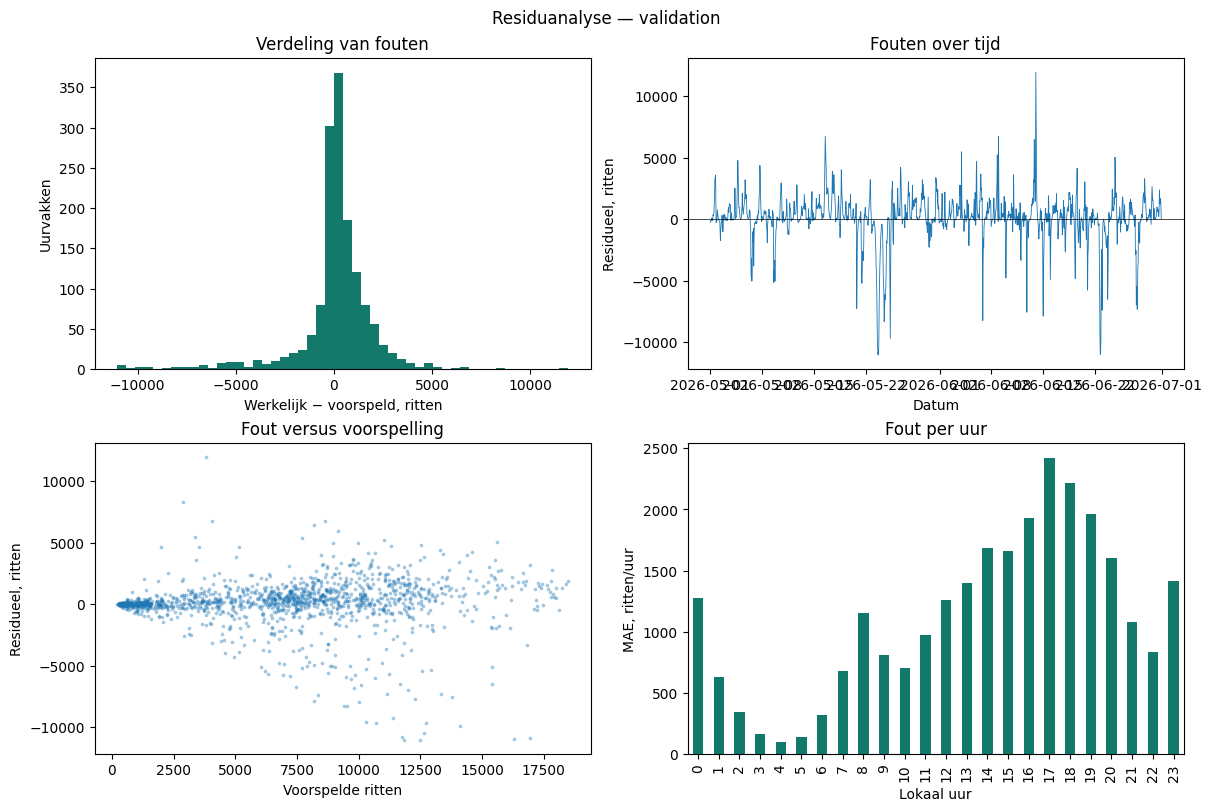

Gemiddelde bias: 105.00 ritten/uur. Het uur met de hoogste MAE is 17:00 (2422.61 ritten/uur). Overblijvende patronen wijzen op beperkingen. Eindtestdiagnostiek wordt uitsluitend achteraf beschreven en leidt niet tot nieuwe tuning onder dezelfde eindtestclaim.

,weekday,MAE,bias,n
0,0,1249.698235,-46.354453,216
1,1,837.733136,398.650639,216
2,2,905.994113,228.853450,192
3,3,832.448689,223.062460,192
4,4,859.539685,304.258624,216
5,5,1793.238662,-505.899364,216
6,6,1268.202864,159.282670,216


,season,MAE,bias,n
0,lente,1159.356232,103.492985,744
1,zomer,1068.107082,106.549592,720


In [5]:
show('residual_validation')
table('validation_errors_by_weekday.csv')
table('validation_errors_by_season.csv')

## Grootste fouten

Residual = actual − prediction; positief betekent onderschatting. Bekijk uur, seizoen en drukte. Een normale verdeling maakt een model niet perfect. Weer en evenementen zijn mogelijke ontbrekende factoren, geen bewezen oorzaak van één fout.

In [6]:
residuals=pd.read_csv(REPORTS/'validation_residuals.csv')
display(residuals.nlargest(10,'absolute_error'))
display(pd.DataFrame([{'gemiddelde_bias':residuals.residual.mean(),'mediaan_absolute_fout':residuals.absolute_error.median()}]))

,timestamp,rides,predicted_rides,residual,absolute_error,hour,weekday,month,season
1056,2026-06-14 00:00:00,15757,3808.407536,11948.592464,11948.592464,0,6,6,zomer
546,2026-05-23 18:00:00,815,11849.423930,-11034.423930,11034.423930,18,5,5,lente
544,2026-05-23 16:00:00,1493,12504.151268,-11011.151268,11011.151268,16,5,5,lente
1266,2026-06-22 18:00:00,5288,16287.259560,-10999.259560,10999.259560,18,0,6,zomer
1265,2026-06-22 17:00:00,6059,16929.669350,-10870.669350,10870.669350,17,0,6,zomer
545,2026-05-23 17:00:00,978,11756.381667,-10778.381667,10778.381667,17,5,5,lente
543,2026-05-23 15:00:00,2176,12634.417641,-10458.417641,10458.417641,15,5,5,lente
1267,2026-06-22 19:00:00,4219,14122.483881,-9903.483881,9903.483881,19,0,6,zomer
584,2026-05-25 08:00:00,1002,10697.403378,-9695.403378,9695.403378,8,0,5,lente
542,2026-05-23 14:00:00,3051,12716.058483,-9665.058483,9665.058483,14,5,5,lente


,gemiddelde_bias,mediaan_absolute_fout
0,104.996235,550.395859


## 18. Definitieve selectie en eenmalige eindtest

De kleinste validatie-RMSE wint; binnen 1% kiezen we het eenvoudigere model. Daarna wordt opnieuw gefit op geschikte data tot eind juni. Het vaste model voorspelt iedere testdag met alleen op dat moment bekende historie. Testdiagnostiek is uitsluitend een eindrapport.

De vooraf vastgelegde eenvoudigheidsrang betreft modeltypen: weekbaseline → Ridge → Random Forest → LightGBM. Binnen dezelfde familie kiest de laagste validatie-RMSE. Het aantal bomen en de diepte krijgen geen afzonderlijke complexiteitsrang. De RF-tuning levert slechts circa 0,27% extra validatiewinst tegenover de oorspronkelijke RF; het grotere uiteindelijke artefact is circa 647 MiB. Die praktische kosten moeten naast de score worden beoordeeld.

In [7]:
selection = report('model_selection.json')
final = report('final_evaluation.json')
display(pd.DataFrame([{'model':final['selected_model'],**final['metrics']},{'model':'seasonal_naive',**final['baseline_metrics']}]))
display(Markdown(f"Eindtest-RMSE-verbetering: **{final['RMSE_improvement_percent']:.2f}%**. MSE-verschil, weekbootstrap-95%-CI: {final['MSE_gain_week_bootstrap_ci95']}. {final['ci_limitation']}"))

,model,RMSE,MAE,R2
0,tuned_random_forest,1979.507160,1076.225847,0.828015
1,seasonal_naive,2608.777506,1453.528226,0.701289


Eindtest-RMSE-verbetering: **24.12%**. MSE-verschil, weekbootstrap-95%-CI: [1161795.8570921829, 4198151.224649241]. Slechts circa negen weekblokken; onzekerheidsinterval is indicatief en veronderstelt beperkte afhankelijkheid.

Deze figuur toont het geregistreerde patroon. De berekende interpretatie onder de grafiek beschrijft de betekenis en beperking.

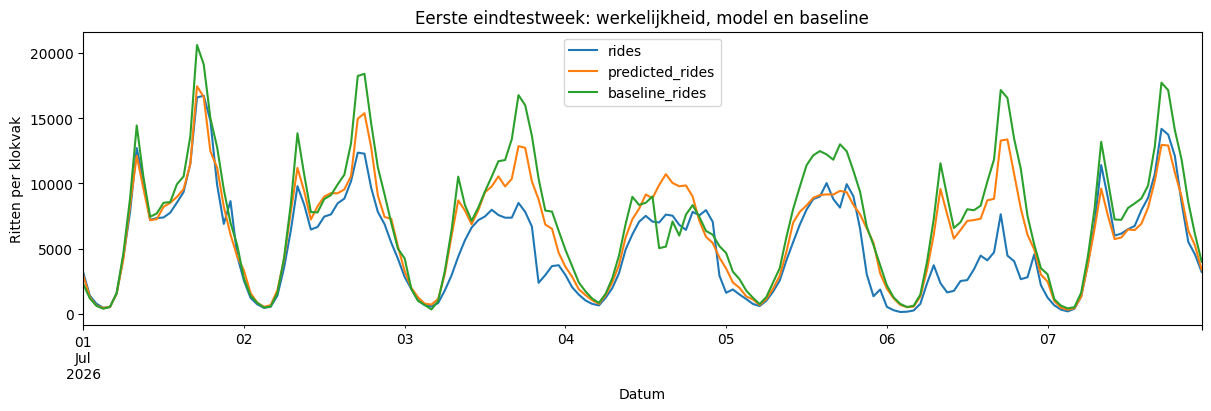

Over de volledige eindtest is de model-RMSE 1979.51, tegenover 2608.78 voor het vorige weekuur. Verbetering: 24.12%. Iedere dag gebruikt alleen eerder gemeten dagen.

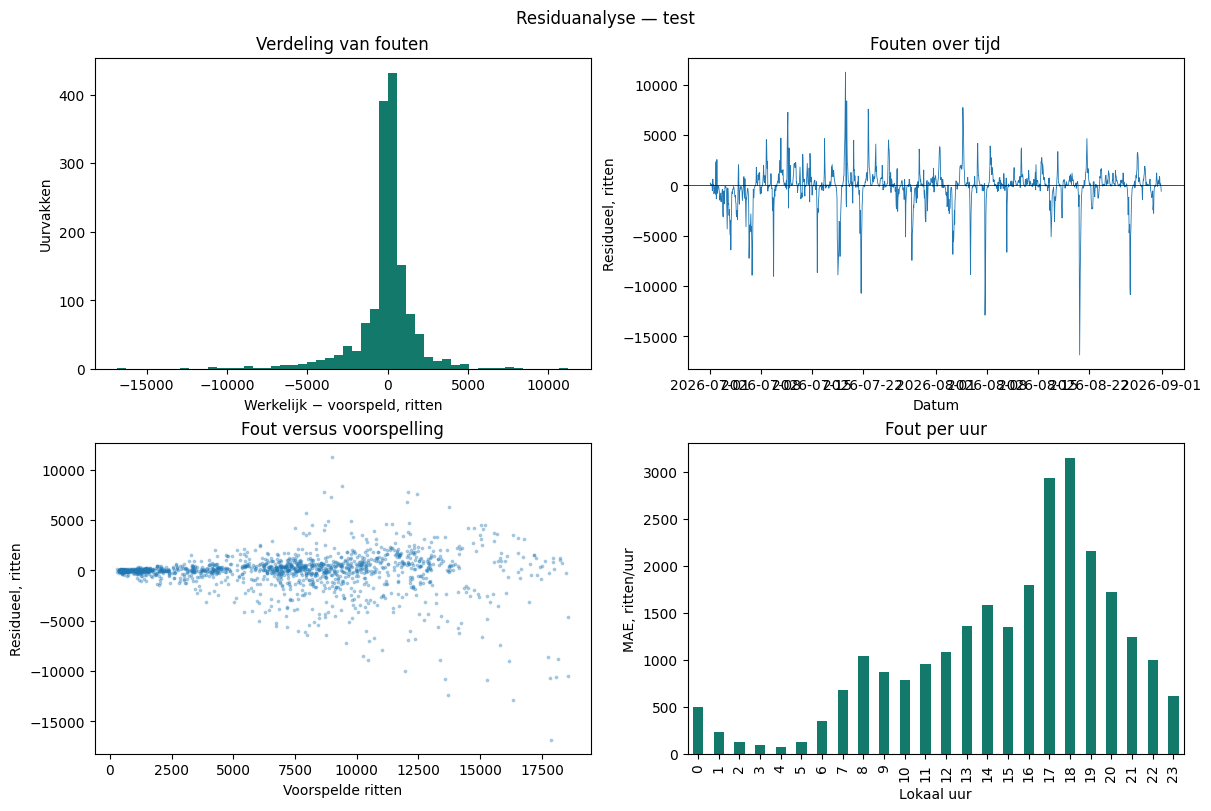

Gemiddelde bias: -127.60 ritten/uur. Het uur met de hoogste MAE is 18:00 (3147.24 ritten/uur). Overblijvende patronen wijzen op beperkingen. Eindtestdiagnostiek wordt uitsluitend achteraf beschreven en leidt niet tot nieuwe tuning onder dezelfde eindtestclaim.

In [8]:
show('test_forecast')
show('residual_test')

## 19. Interpretatie — INTERPRET

Permutation importance wordt op validatie berekend. Correlatie tussen features en onrealistische permutaties beperken de interpretatie. Weer, capaciteit en evenementen ontbreken; geen feature importance bewijst causaliteit.

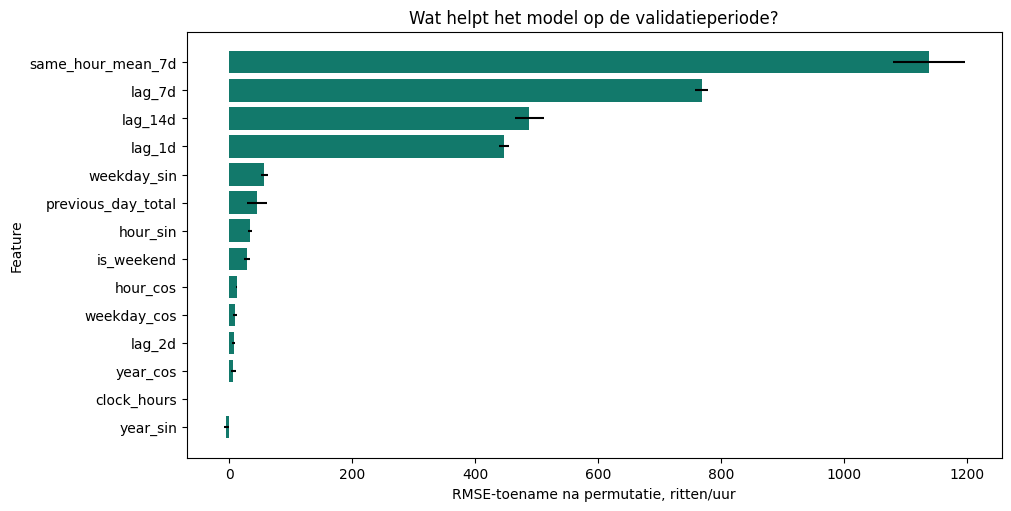

De sterkste gemeten permutation importance hoort bij same_hour_mean_7d: 1137.75 ritten/uur RMSE-toename. Afhankelijke features kunnen elkaars belang maskeren; onafhankelijke permutatie kan onrealistische combinaties maken. Dit toont geen causaliteit.

In [9]:
show('importance')

## Aanvullend: oorspronkelijke vensters, tuning en ablaties

We behouden ook experimenten zonder winst. Dit zijn historische ontwikkelingsbeslissingen; we gebruiken ze nu niet om een nieuwe keuze te maken.

## 16. Modelverbetering

Historische trainingsvensters van twee, vijf en alle jaren zijn eerst met trainings-CV vergeleken. De twee sterkste kandidaten krijgen maximaal twintig configuraties. Feature-ablaties onderzoeken kalender-only en het verwijderen van de 14-dagenlag. Geen zoekstap gebruikt de eindtest.

In [10]:
investigation=report('validation_error_investigation.json')
display(pd.DataFrame([{k:v for k,v in investigation.items() if k not in ['hour_MAE','weekday_MAE','largest_errors']}]))
display(pd.DataFrame(investigation['largest_errors']))

,model_before_improvement,mean_bias,worst_hour,worst_hour_MAE,worst_weekday,worst_weekday_MAE,improvement_experiments,test_used
0,random_forest,83.244514,17,2425.475892,5,1820.27889,Tune model capacity; compare calendar-only wit...,False


,timestamp,rides,predicted_rides,residual,absolute_error,hour,weekday,month,season
0,2026-06-14 00:00:00,15757,3820.128249485271,11936.871750514729,11936.871750514729,0,6,6,zomer
1,2026-06-22 18:00:00,5288,16442.79310017197,-11154.79310017197,11154.79310017197,18,0,6,zomer
2,2026-06-22 17:00:00,6059,16996.820207109944,-10937.820207109944,10937.820207109944,17,0,6,zomer
3,2026-05-23 18:00:00,815,11596.922670283533,-10781.922670283533,10781.922670283533,18,5,5,lente
4,2026-05-23 16:00:00,1493,12190.73404590426,-10697.73404590426,10697.73404590426,16,5,5,lente
5,2026-05-23 17:00:00,978,11625.015103972297,-10647.015103972297,10647.015103972297,17,5,5,lente
6,2026-05-23 15:00:00,2176,12549.346997627637,-10373.346997627637,10373.346997627637,15,5,5,lente
7,2026-05-25 08:00:00,1002,10756.967674697536,-9754.967674697536,9754.967674697536,8,0,5,lente
8,2026-05-23 14:00:00,3051,12596.161073513404,-9545.161073513404,9545.161073513404,14,5,5,lente
9,2026-06-22 16:00:00,2177,11688.262915844096,-9511.262915844096,9511.262915844096,16,0,6,zomer


We bewaren historische vensters en alle tuninginstellingen, ook zonder validatiewinst.

In [11]:
display(pd.DataFrame(report('training_windows.json')).drop(columns='folds'))
for path in sorted(REPORTS.glob('*_tuning.csv')):
    display(Markdown('**'+path.stem+'**'))
    display(pd.read_csv(path)[['configuration','cv_RMSE','parameters']])

,years,model,rows,cv_RMSE
0,2.0,ridge,17520,1576.072219
1,2.0,lightgbm,17520,1504.774563
2,5.0,ridge,43824,1575.824827
3,5.0,lightgbm,43824,1436.839752
4,NaN,ridge,112872,1594.314667
5,NaN,lightgbm,112872,1423.037130


**lightgbm_tuning**

,configuration,cv_RMSE,parameters
0,1,1423.633347,"{""estimator__num_leaves"": 15, ""estimator__n_es..."
1,2,1503.104722,"{""estimator__num_leaves"": 15, ""estimator__n_es..."
2,3,1410.961752,"{""estimator__num_leaves"": 31, ""estimator__n_es..."
3,4,1421.446054,"{""estimator__num_leaves"": 31, ""estimator__n_es..."
4,5,1499.484772,"{""estimator__num_leaves"": 15, ""estimator__n_es..."
5,6,1438.275587,"{""estimator__num_leaves"": 31, ""estimator__n_es..."
6,7,1461.382875,"{""estimator__num_leaves"": 31, ""estimator__n_es..."
7,8,1410.433592,"{""estimator__num_leaves"": 31, ""estimator__n_es..."
8,9,1437.919426,"{""estimator__num_leaves"": 31, ""estimator__n_es..."
9,10,1455.752125,"{""estimator__num_leaves"": 15, ""estimator__n_es..."


**random_forest_tuning**

,configuration,cv_RMSE,parameters
0,1,1485.574606,"{""estimator__n_estimators"": 320, ""estimator__m..."
1,2,1485.152935,"{""estimator__n_estimators"": 240, ""estimator__m..."
2,3,1475.817191,"{""estimator__n_estimators"": 240, ""estimator__m..."
3,4,1433.759353,"{""estimator__n_estimators"": 320, ""estimator__m..."
4,5,1462.581949,"{""estimator__n_estimators"": 320, ""estimator__m..."
5,6,1459.088472,"{""estimator__n_estimators"": 240, ""estimator__m..."


Dit protocol legt de oorspronkelijke zoekbegroting, seed en folds vast, zonder eindtestinformatie.

In [12]:
display(pd.DataFrame([report('tuning_protocol.json')]))

,created_at,models,configurations,seed,fold_fingerprint,test_used,reason
0,2026-10-09T10:46:52.600937+00:00,"[lightgbm, random_forest]","{'lightgbm': 20, 'random_forest': 6}",42,59238f467d526664e56943f96d102928ede96e4e371fec...,False,Resource budget fixed before tuning: Random Fo...


## Gedeelde deploymentfunctie

Deze demonstratiedag komt uit ontwikkeling en is geen onafhankelijke prestatietest. API en Streamlit gebruiken dezelfde predict_day.

In [13]:
from citibike.inference import predict_day
history=pd.read_parquet(DATA/'NYC_hourly_development.parquet')
day=history.timestamp.max().normalize()
display(predict_day(day,history[history.timestamp<day]))

,timestamp,clock_hours,predicted_rides
0,2026-04-30 00:00:00,1,1094.383420
1,2026-04-30 01:00:00,1,561.665549
2,2026-04-30 02:00:00,1,341.733590
3,2026-04-30 03:00:00,1,253.783953
4,2026-04-30 04:00:00,1,334.219510
5,2026-04-30 05:00:00,1,1055.889292
6,2026-04-30 06:00:00,1,3158.959519
7,2026-04-30 07:00:00,1,7574.195047
8,2026-04-30 08:00:00,1,11860.514053
9,2026-04-30 09:00:00,1,8874.899801


## Beperkingen en eindcontrole

Restpatronen en twee zomermaanden als eindtest beperken generalisatie. Een nieuwe modelkeuze vraagt een nieuwe onafhankelijke testperiode. Zie OPDRACHTCONTROLE.md voor runnerregistratie, live update en AWS-cloudbewijs.

In [14]:
display(Markdown((REPORTS/'MODEL_CARD.md').read_text(encoding='utf-8')))
display(pd.DataFrame([report('verification.json')]))
display(pd.DataFrame([report('test_results.json')]).drop(columns='test_names'))

# Citi Bike-modelkaart

Gekozen model: **tuned_random_forest**. Het voorspelt geregistreerde NYC-vertrekken
per lokaal uurvak, voor één volledige kalenderdag vanaf 00:00 New York-tijd.
Veertien volledige voorafgaande dagen zijn nodig. Jersey City is uitgesloten.

| Metriek | Eindmodel | Vorig weekuur |
|---|---:|---:|
| RMSE, ritten/uur | 1979.51 | 2608.78 |
| MAE, ritten/uur | 1076.23 | 1453.53 |
| R² | 0.8280 | 0.7013 |

RMSE-verbetering: 24.12%. Eindtest juli–augustus 2026,
1488 klokvakken. Selectie en tuning gebruikten deze uitkomsten niet.
Het model blijft vast; eerder gemeten testdagen worden daarna historische invoer.
Het artefact is na de eindtest niet opnieuw getraind.

Dit is geregistreerd gebruik, geen onvervulde vraag of beschikbaarheid per station.
Weer, evenementen en capaciteit ontbreken. Feature importance toont geen causaliteit.
Historische schema's en gebruik veranderen; twee testmaanden dekken niet alle seizoenen.
Het weekbootstrapinterval bevat weinig blokken en geeft beperkte zekerheid.
De actuele maandarchieven leveren niet automatisch de recente historie voor morgen.
De backtest veronderstelt een externe bron met vóór 00:00 beschikbare uurtellingen.
Publicatie-, ingestie- en rekenlatentie zijn niet gemodelleerd. De prestaties gelden
onder dit invoercontract; een operationele tellingenfeed moet apart worden gerealiseerd.

Hertrain offline met de README-commando's. Modelbestanden staan lokaal en buiten Git.
Bronnen, code, packageversies, seeds, splits en fingerprints zijn vastgelegd.
AWS-training blijft open voor de volledige schoolopdracht.


,python_version,python_executable,partitions_verified,manifest_fingerprint_verified,pycaret_identical_folds,offline_app_predictions_equal,pycaret_identical_train_validation_rows,fixed_configuration_retraining_verified,retraining_seconds,retraining_prediction_max_difference,streamlit_form_predictions_verified,manifest_required_fields_verified,model_ignored_by_git,evaluated_model_is_deployed,prediction_code_and_packages_locked,raw_rows,retained_rows,modeling_rows,test_rows
0,"3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.19...",C:\Deeplearning\CloudAI\Citybike_full\.venv\Sc...,291,True,True,True,True,True,154.985927,3.637979e-12,True,True,True,True,True,355199439,330714664,114336,1488


,executed_at,command,tests,passed,failed,skipped,code_version
0,2026-10-14T15:08:34.643415+00:00,.venv/Scripts/python.exe -X utf8 tools/run_tes...,30,30,0,0,{'fingerprint': '83eb6c1d0b553030f9ad8659cbb1e...
